In [ ]:
import numpy as np


Linear Regression


In [ ]:
class linearRegression():
  #initiating the parameters
    def __init__(self, learning_rate=0.001, no_of_iterations=1000):
      self.learning_rate = learning_rate
      self.no_of_iterations = no_of_iterations

    def fit(self, X, y):
#no of training examples & no of features
      self.m, self.n = X.shape
      self.w = np.zeros(self.n)
      self.b = 0
      self.X = X
      self.y = y

#gradient descent
      for i in range(self.no_of_iterations):
        self.update_weights()

    def update_weights(self):
      y_prediction = self.predict(self.X)
      dw = - (2 * (self.X.T).dot(self.y - y_prediction)) / self.m

      db = - 2 * np.sum(self.y - y_prediction)/self.m
      #updating the weights
      self.w = self.w - self.learning_rate * dw
      self.b = self.b - self.learning_rate * db
    def predict(self, X):
      return X.dot(self.w) + self.b

In [ ]:
#importing the dependencies
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

data preprocessing

In [ ]:
salary_data=pd.read_csv('salary_data.csv')

In [ ]:
salary_data.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [ ]:
salary_data.shape

(30, 2)

In [ ]:
#no of null values
salary_data.isnull().sum()

,0
YearsExperience,0
Salary,0


spliting the feature& target

In [ ]:
x=salary_data.iloc[:,:-1].values
y=salary_data.iloc[:,-1].values

In [ ]:
print(y)

[ 39343  46205  37731  43525  39891  56642  60150  54445  64445  57189
  63218  55794  56957  57081  61111  67938  66029  83088  81363  93940
  91738  98273 101302 113812 109431 105582 116969 112635 122391 121872]


In [ ]:
print(x)

[[ 1.1]
 [ 1.3]
 [ 1.5]
 [ 2. ]
 [ 2.2]
 [ 2.9]
 [ 3. ]
 [ 3.2]
 [ 3.2]
 [ 3.7]
 [ 3.9]
 [ 4. ]
 [ 4. ]
 [ 4.1]
 [ 4.5]
 [ 4.9]
 [ 5.1]
 [ 5.3]
 [ 5.9]
 [ 6. ]
 [ 6.8]
 [ 7.1]
 [ 7.9]
 [ 8.2]
 [ 8.7]
 [ 9. ]
 [ 9.5]
 [ 9.6]
 [10.3]
 [10.5]]


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size = 0.2, random_state=2)

training the linear regression model

In [ ]:
model = linearRegression(learning_rate=0.02, no_of_iterations=1000)

In [ ]:
model.fit(X_train, Y_train)

In [ ]:
print("Weight=", model.w[0])
print('bias=', model.b)

Weight= 9570.888860991548
bias= 24384.029598697263


predict salary for test data

In [ ]:
test_data_prediction = model.predict(X_test)

In [ ]:
print(test_data_prediction)

[36826.18511799 34912.00734579 67453.02947316 59796.31838437
 92337.34051174 81809.36276465]


visualization of data

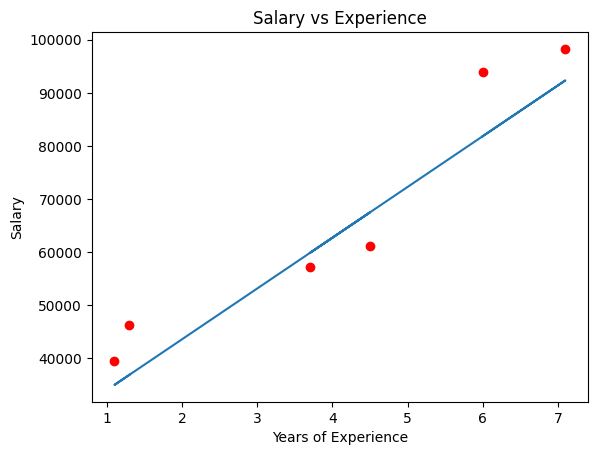

In [ ]:
plt.scatter(X_test, Y_test, color='red')
plt.plot(X_test, test_data_prediction)
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Salary vs Experience')
plt.show()

In [ ]:
#check the accuracy score
from sklearn.metrics import r2_score
r2_score(Y_test, test_data_prediction)

0.88863795514416